# Customer Churn Analysis and Prediction using Logistic Regression

**IDS Case Study – Review 2**
**Data Analysis using R**

Boyina Abhinav
Roll No.: 160124771032

## 1. Introduction / Background

- Customer churn refers to customers discontinuing their services with a company.
- Customer retention is important because losing existing customers can affect business revenue and growth.
- Customer data can be analyzed to identify patterns and factors associated with churn.
- This case study focuses on analyzing telecom customer data and predicting whether a customer is likely to churn.

## 2. Problem Statement

- Telecommunication companies need to identify customers who are likely to leave their services.
- The challenge is to understand which customer and service characteristics are associated with churn.
- The case study will use customer information to analyze churn patterns and develop a prediction model.
- Logistic Regression will be used because the target outcome, Churn, has two categories: Yes and No.

## 3. Objectives

1. Analyze customer demographic and service-related factors associated with churn.
2. Clean, preprocess, and explore the customer churn dataset using R.
3. Identify patterns and factors that may influence customer churn.
4. Develop a Logistic Regression model to predict customer churn.

## 4. Dataset

| Item | Description |
|---|---|
| Dataset | Telco Customer Churn |
| Records | 7,043 customer records |
| Variables | 21 columns |
| Target Variable | Churn – *Yes*: customer churned, *No*: customer stayed |
| Important Variables | Tenure, Contract, Internet Service, Monthly Charges, Total Charges, Payment Method, Senior Citizen and other customer/service attributes |

> **Before you run this notebook:** place the dataset file `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder as this notebook (or change `data_file` in Section 6.1).

## 5. Proposed Methodology

**Dataset → Data Cleaning → Preprocessing → EDA & Visualization → Logistic Regression → Model Evaluation**

R is used throughout the workflow for data preparation, analysis, visualization and model development.

| Step | Section in this notebook |
|---|---|
| 1. Dataset | 6. Dataset |
| 2. Data Cleaning | 7. Data Cleaning |
| 3. Preprocessing | 8. Preprocessing |
| 4. EDA & Visualization | 9. EDA & Visualization |
| 5. Logistic Regression | 10. Logistic Regression |
| 6. Model Evaluation | 11. Model Evaluation |

## Setup

Install any missing packages and load the libraries used in this notebook.

In [ ]:
required_pkgs<-c("tidyverse","caret","pROC","scales","car")
missing_pkgs<-required_pkgs[!(required_pkgs %in% rownames(installed.packages()))]
if (length(missing_pkgs)>0) {
  install.packages(missing_pkgs,repos="https://cloud.r-project.org")
}
suppressPackageStartupMessages({
  library(tidyverse)   # dplyr, ggplot2, readr, tidyr ...
  library(caret)       # train/test split, confusion matrix
  library(pROC)        # ROC curve and AUC
  library(scales)      # percent labels on plots
})
options(repr.plot.width = 8, repr.plot.height = 4.5)
theme_set(theme_minimal(base_size = 13))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘prodlim’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘recipes’, ‘reshape2’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’




## 6. Dataset

### 6.1 Load the data

In [ ]:
data_file<-"WA_Fn-UseC_-Telco-Customer-Churn.csv"
if (!file.exists(data_file)){
  stop("Dataset not found. Put '",data_file,"' in the working directory: ",getwd())
}
churn_raw<-read.csv(data_file,stringsAsFactors=FALSE)
cat("Records  :",nrow(churn_raw),"\n")
cat("Variables:",ncol(churn_raw),"\n")

Records  : 7043 
Variables: 21 


### 6.2 First look at the data

In [ ]:
head(churn_raw)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,⋯,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
1,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,⋯,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
2,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,⋯,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
3,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,⋯,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,⋯,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
5,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,⋯,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
6,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,⋯,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes


In [ ]:
glimpse(churn_raw)

Rows: 7,043
Columns: 21
$ customerID       <chr> "7590-VHVEG", "5575-GNVDE", "3668-QPYBK", "7795-CFOCW…
$ gender           <chr> "Female", "Male", "Male", "Male", "Female", "Female",…
$ SeniorCitizen    <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Partner          <chr> "Yes", "No", "No", "No", "No", "No", "No", "No", "Yes…
$ Dependents       <chr> "No", "No", "No", "No", "No", "No", "Yes", "No", "No"…
$ tenure           <int> 1, 34, 2, 45, 2, 8, 22, 10, 28, 62, 13, 16, 58, 49, 2…
$ PhoneService     <chr> "No", "Yes", "Yes", "No", "Yes", "Yes", "Yes", "No", …
$ MultipleLines    <chr> "No phone service", "No", "No", "No phone service", "…
$ InternetService  <chr> "DSL", "DSL", "DSL", "DSL", "Fiber optic", "Fiber opt…
$ OnlineSecurity   <chr> "No", "Yes", "Yes", "Yes", "No", "No", "No", "Yes", "…
$ OnlineBackup     <chr> "Yes", "No", "Yes", "No", "No", "No", "Yes", "No", "N…
$ DeviceProtection <chr> "No", "Yes", "No", "Yes", "No", "Yes", "No", "No", "Y…
$ TechSupport   

In [ ]:
summary(churn_raw)

     customerID         gender     SeniorCitizen         Partner    
 Length   :7043   Length   :7043   Min.   :0.0000   Length   :7043  
 N.unique :7043   N.unique :   2   1st Qu.:0.0000   N.unique :   2  
 N.blank  :   0   N.blank  :   0   Median :0.0000   N.blank  :   0  
 Min.nchar:  10   Min.nchar:   4   Mean   :0.1621   Min.nchar:   2  
 Max.nchar:  10   Max.nchar:   6   3rd Qu.:0.0000   Max.nchar:   3  
                                   Max.   :1.0000                   
                                                                    
     Dependents       tenure         PhoneService    MultipleLines 
 Length   :7043   Min.   : 0.00   Length   :7043   Length   :7043  
 N.unique :   2   1st Qu.: 9.00   N.unique :   2   N.unique :   3  
 N.blank  :   0   Median :29.00   N.blank  :   0   N.blank  :   0  
 Min.nchar:   2   Mean   :32.37   Min.nchar:   2   Min.nchar:   2  
 Max.nchar:   3   3rd Qu.:55.00   Max.nchar:   3   Max.nchar:  16  
                  Max.   :72.00         

### 6.3 Target variable

The target variable, **Churn**, has two categories (*Yes* / *No*), which makes this a binary classification problem.

In [ ]:
table(churn_raw$Churn)
round(prop.table(table(churn_raw$Churn))*100,2)


  No  Yes 
5174 1869 


   No   Yes 
73.46 26.54 

## 7. Data Cleaning

### 7.1 Missing values, blanks and duplicates

In [ ]:
# Explicit NA values per column
colSums(is.na(churn_raw))

customerID           gender    SeniorCitizen          Partner 
               0                0                0                0 
      Dependents           tenure     PhoneService    MultipleLines 
               0                0                0                0 
 InternetService   OnlineSecurity     OnlineBackup DeviceProtection 
               0                0                0                0 
     TechSupport      StreamingTV  StreamingMovies         Contract 
               0                0                0                0 
PaperlessBilling    PaymentMethod   MonthlyCharges     TotalCharges 
               0                0                0               11 
           Churn 
               0

In [ ]:
# Blank strings (they are not NA,so they are easy to miss)
blank_counts<-sapply(churn_raw,function(x) sum(trimws(as.character(x)) == "",na.rm=TRUE))
blank_counts[blank_counts>0]

named integer(0)

In [ ]:
# Duplicate customers
cat("Duplicate customerID values:",sum(duplicated(churn_raw$customerID)),"\n")

Duplicate customerID values: 0 


### 7.2 Convert `TotalCharges` to numeric

Initial dataset inspection indicates that **TotalCharges requires numerical conversion** during preprocessing. It is read as text because some entries are blank, so it is converted with `as.numeric()` after trimming spaces.

In [ ]:
churn<-churn_raw
churn$TotalCharges<-as.numeric(trimws(churn$TotalCharges))
cat("TotalCharges class now:",class(churn$TotalCharges),"\n")
cat("Missing TotalCharges  :",sum(is.na(churn$TotalCharges)),"\n")

TotalCharges class now: numeric 
Missing TotalCharges  : 11 


In [ ]:
# Inspect the rows where TotalCharges could not be converted
churn %>%
  filter(is.na(TotalCharges)) %>%
  select(customerID,tenure,MonthlyCharges,TotalCharges,Churn)

customerID,tenure,MonthlyCharges,TotalCharges,Churn
<chr>,<int>,<dbl>,<dbl>,<chr>
4472-LVYGI,0,52.55,NA,No
3115-CZMZD,0,20.25,NA,No
5709-LVOEQ,0,80.85,NA,No
4367-NUYAO,0,25.75,NA,No
1371-DWPAZ,0,56.05,NA,No
7644-OMVMY,0,19.85,NA,No
3213-VVOLG,0,25.35,NA,No
2520-SGTTA,0,20.00,NA,No
2923-ARZLG,0,19.70,NA,No


In this dataset, 11 rows have a blank `TotalCharges` value. All of them are customers with `tenure = 0` (not yet billed) and `Churn = No`. They make up about 0.16% of the data, so they are removed. Expected size after cleaning: 7,032 rows.

In [ ]:
rows_before<-nrow(churn)
churn<-churn %>% filter(!is.na(TotalCharges))
cat("Rows before:",rows_before,"| Rows after:",nrow(churn),
    "| Removed:",rows_before - nrow(churn),"\n")

Rows before: 7043 | Rows after: 7032 | Removed: 11 


## 8. Preprocessing

### 8.1 Drop the identifier and tidy categorical levels

- `customerID` is only an identifier, so it is dropped.
- `SeniorCitizen` is stored as 0/1, so it is converted to *No* / *Yes* like the other categorical variables.
- Levels such as *"No phone service"* and *"No internet service"* carry the same information as *"No"* (it is already captured by `PhoneService` / `InternetService`), so they are merged into *"No"*.

In [ ]:
internet_dependent<-c("OnlineSecurity","OnlineBackup","DeviceProtection",
                        "TechSupport","StreamingTV","StreamingMovies")

churn<-churn %>%
  select(-customerID) %>%
  mutate(
    SeniorCitizen=ifelse(SeniorCitizen==1,"Yes","No"),
    MultipleLines=ifelse(MultipleLines== "No phone service","No",MultipleLines),
    across(all_of(internet_dependent),~ifelse(.x == "No internet service","No",.x))
  )

### 8.2 Convert categorical variables to factors

In [ ]:
churn<-churn %>% mutate(across(where(is.character),as.factor))
# 'No' is the reference level, so the model estimates the probability of Churn = 'Yes'
churn$Churn<-relevel(churn$Churn,ref="No")
str(churn)

'data.frame':	7032 obs. of  20 variables:
 $ gender          : Factor w/ 2 levels "Female","Male": 1 2 2 2 1 1 2 1 1 2 ...
 $ SeniorCitizen   : Factor w/ 2 levels "No","Yes": 1 1 1 1 1 1 1 1 1 1 ...
 $ Partner         : Factor w/ 2 levels "No","Yes": 2 1 1 1 1 1 1 1 2 1 ...
 $ Dependents      : Factor w/ 2 levels "No","Yes": 1 1 1 1 1 1 2 1 1 2 ...
 $ tenure          : int  1 34 2 45 2 8 22 10 28 62 ...
 $ PhoneService    : Factor w/ 2 levels "No","Yes": 1 2 2 1 2 2 2 1 2 2 ...
 $ MultipleLines   : Factor w/ 2 levels "No","Yes": 1 1 1 1 1 2 2 1 2 1 ...
 $ InternetService : Factor w/ 3 levels "DSL","Fiber optic",..: 1 1 1 1 2 2 2 1 2 1 ...
 $ OnlineSecurity  : Factor w/ 2 levels "No","Yes": 1 2 2 2 1 1 1 2 1 2 ...
 $ OnlineBackup    : Factor w/ 2 levels "No","Yes": 2 1 2 1 1 1 2 1 1 2 ...
 $ DeviceProtection: Factor w/ 2 levels "No","Yes": 1 2 1 2 1 2 1 1 2 1 ...
 $ TechSupport     : Factor w/ 2 levels "No","Yes": 1 1 1 2 1 1 1 1 2 1 ...
 $ StreamingTV     : Factor w/ 2 levels "No","Yes

### 8.3 Train / test split

The data is split 70% / 30% with stratified sampling, so the proportion of churned customers is similar in both parts. A seed is set so the results are reproducible.

In [ ]:
set.seed(123)
train_idx<-createDataPartition(churn$Churn,p=0.70,list=FALSE)
train<-churn[train_idx, ]
test<-churn[-train_idx, ]
cat("Training rows:",nrow(train),"| Test rows:",nrow(test),"\n\n")
cat("Churn share in training set:\n"); print(round(prop.table(table(train$Churn)),3))
cat("Churn share in test set:\n");     print(round(prop.table(table(test$Churn)),3))

Training rows: 4924 | Test rows: 2108 

Churn share in training set:

   No   Yes 
0.734 0.266 
Churn share in test set:

   No   Yes 
0.734 0.266 


## 9. EDA & Visualization

Exploratory analysis is done on the cleaned full dataset to identify patterns and factors that may influence customer churn.

### 9.1 Overall churn distribution

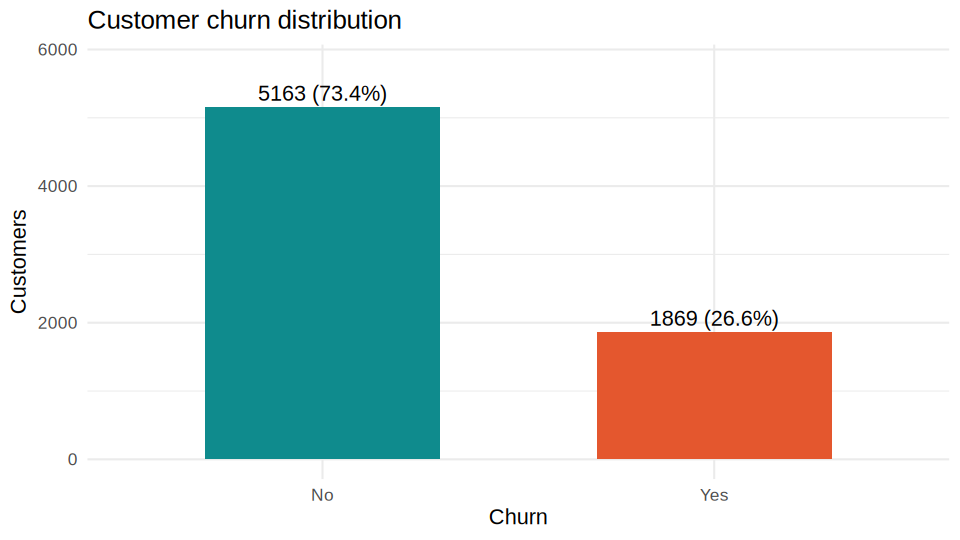

In [ ]:
churn %>%
  count(Churn) %>%
  mutate(pct=n/sum(n)) %>%
  ggplot(aes(x=Churn,y=n,fill=Churn)) +
  geom_col(width=0.6) +
  geom_text(aes(label=paste0(n," (",percent(pct,accuracy = 0.1),")")),vjust=-0.4) +
  scale_fill_manual(values=c("No"="#0F8B8D","Yes"="#E4572E")) +
  labs(title ="Customer churn distribution",x="Churn",y="Customers") +
  theme(legend.position="none") +
  expand_limits(y=max(table(churn$Churn))*1.12)

### 9.2 Churn by customer and service characteristics

Each bar shows the share of customers who churned (*Yes*) and stayed (*No*) within each category.

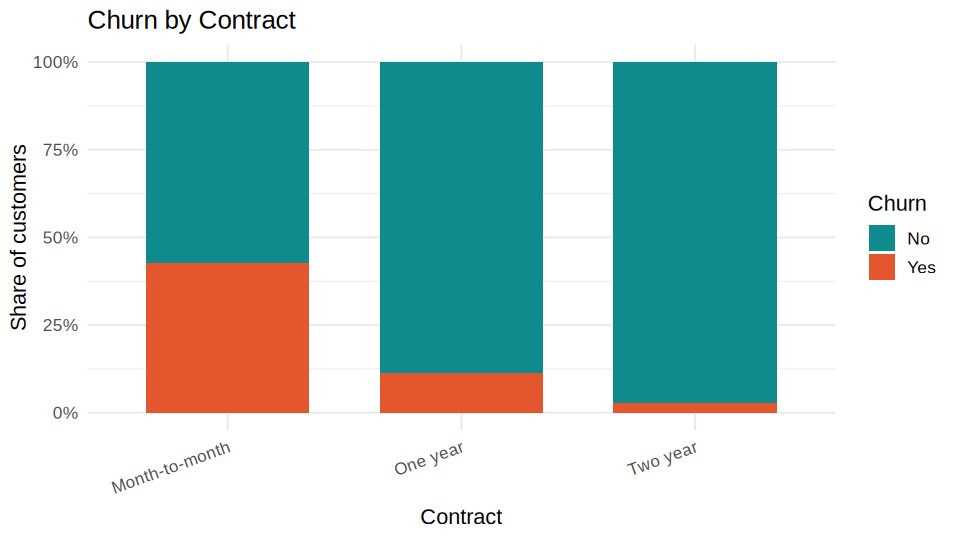

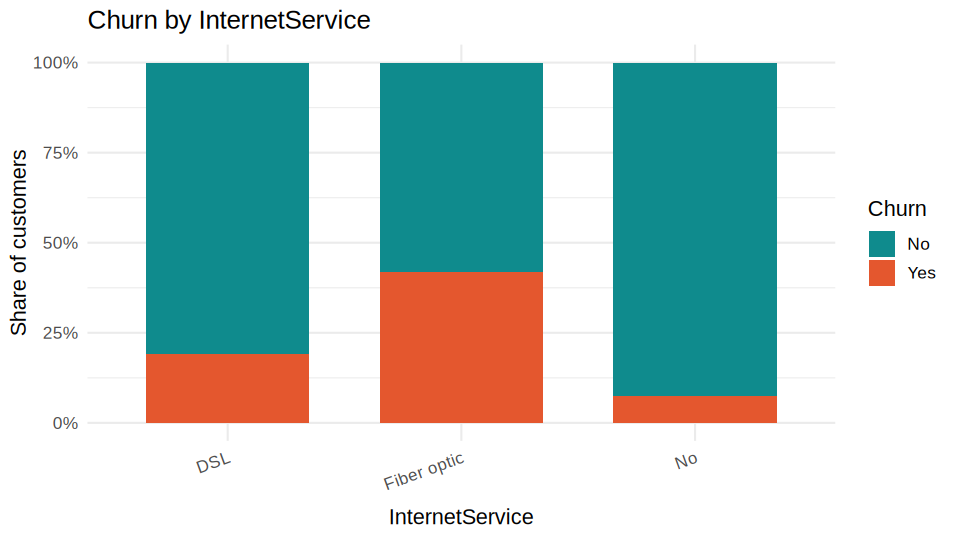

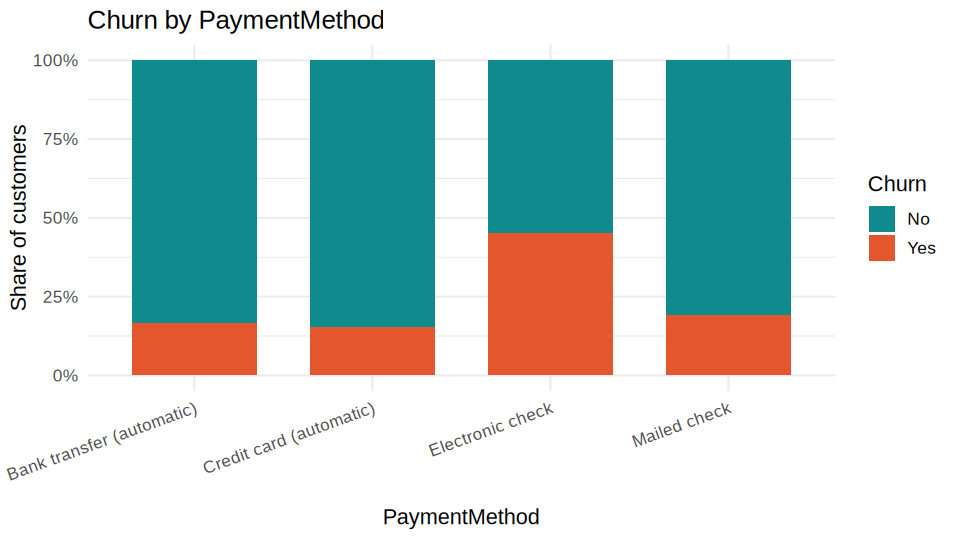

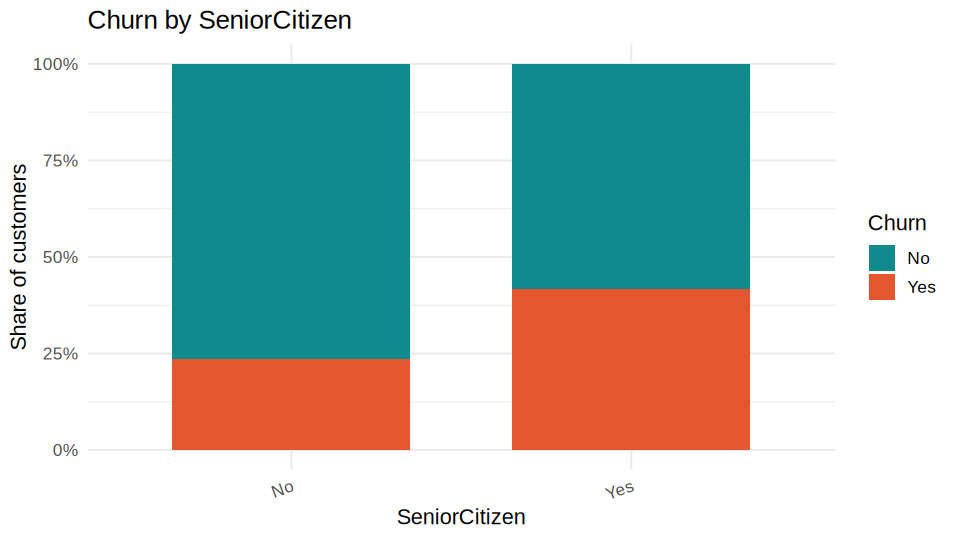

In [ ]:
plot_churn_by <- function(var) {
  ggplot(churn, aes(x = .data[[var]], fill = Churn)) +
    geom_bar(position = "fill", width = 0.7) +
    scale_y_continuous(labels = percent) +
    scale_fill_manual(values = c("No" = "#0F8B8D", "Yes" = "#E4572E")) +
    labs(title = paste("Churn by", var), x = var, y = "Share of customers") +
    theme(axis.text.x = element_text(angle = 20, hjust = 1))
}

for (v in c("Contract", "InternetService", "PaymentMethod", "SeniorCitizen")) {
  print(plot_churn_by(v))
}

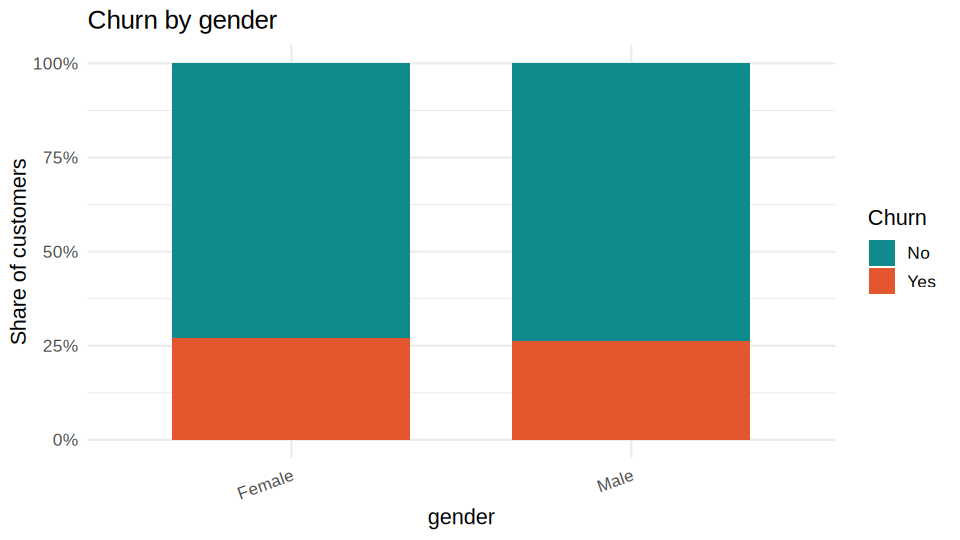

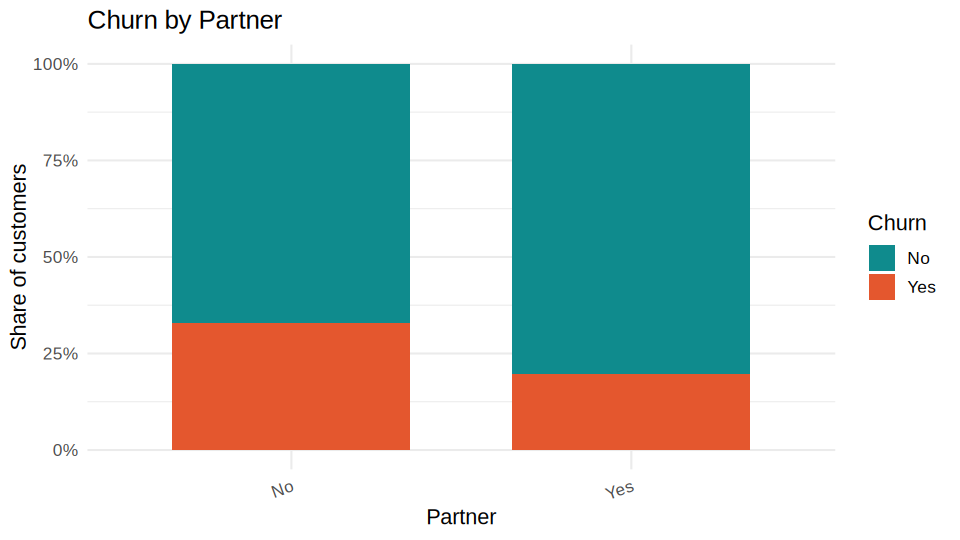

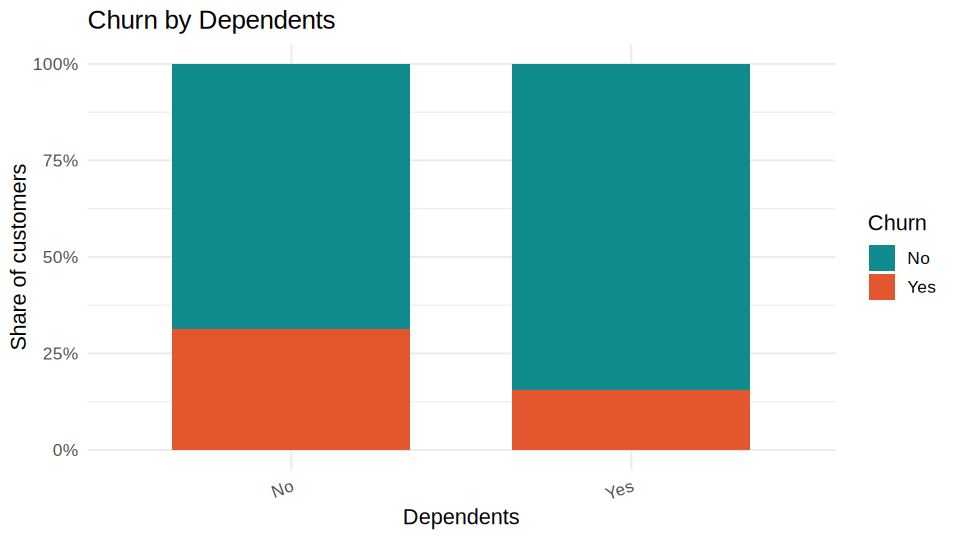

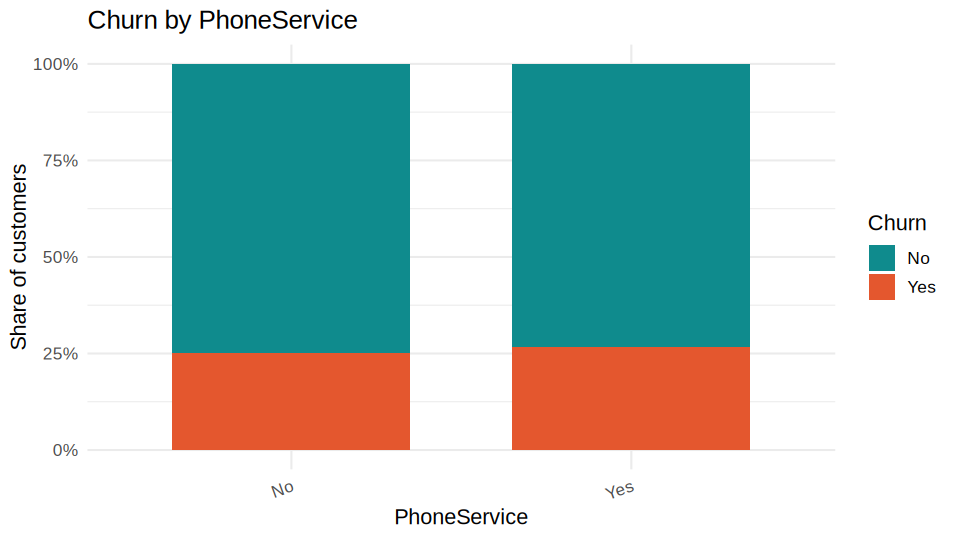

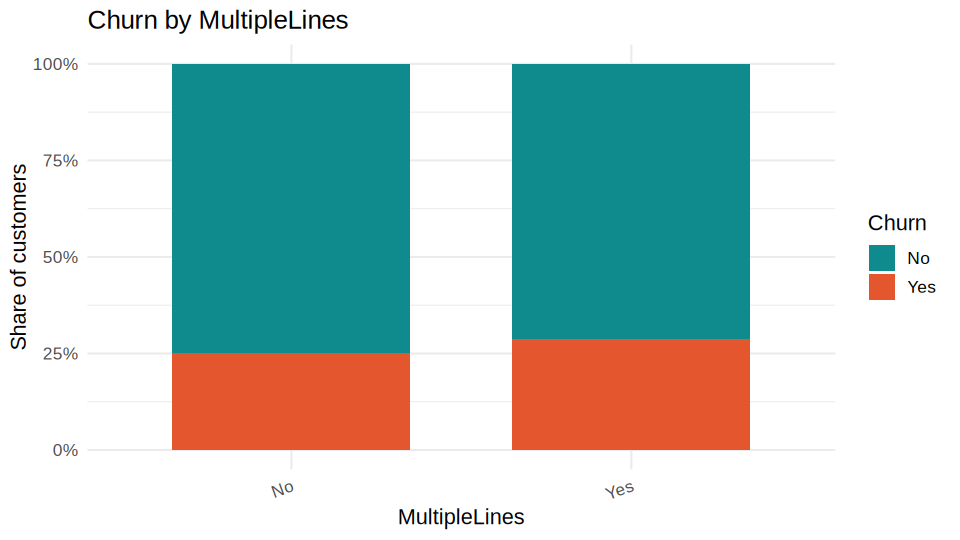

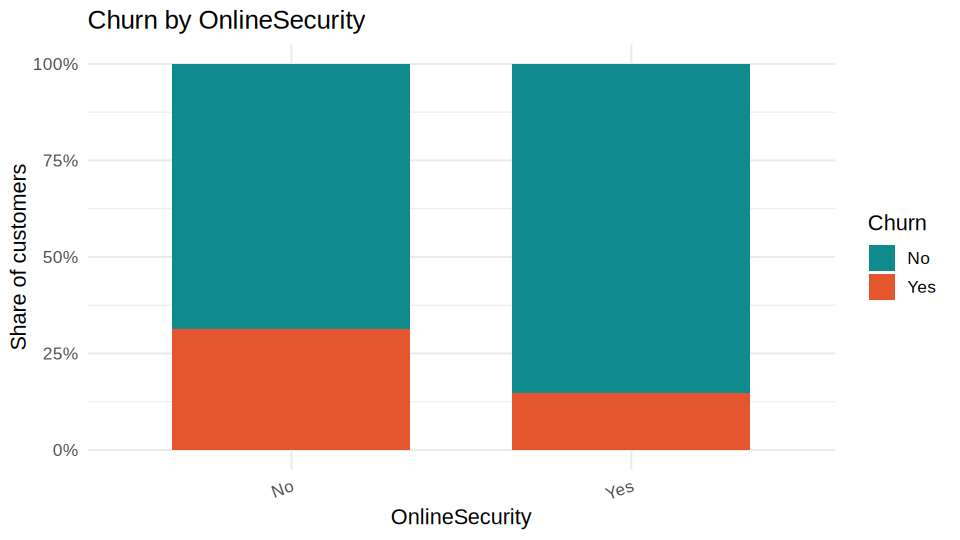

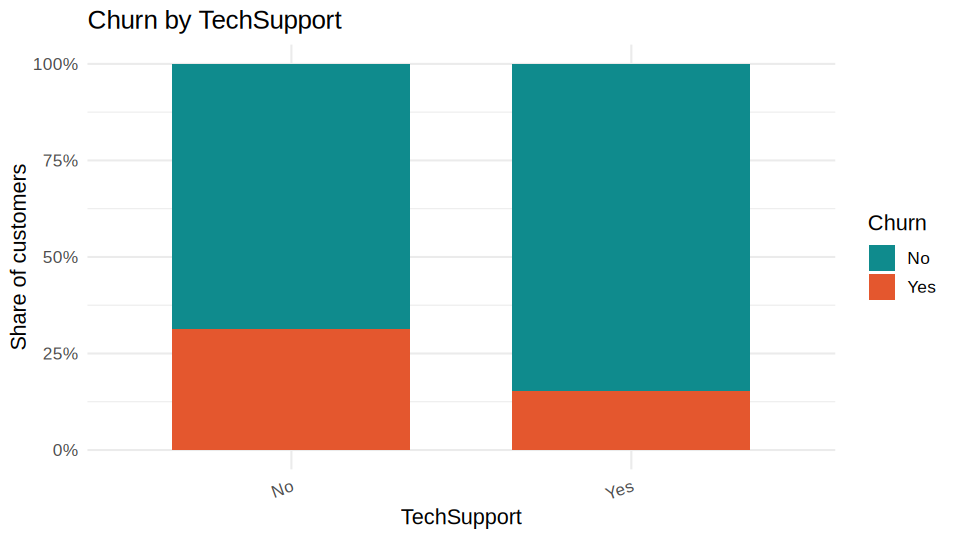

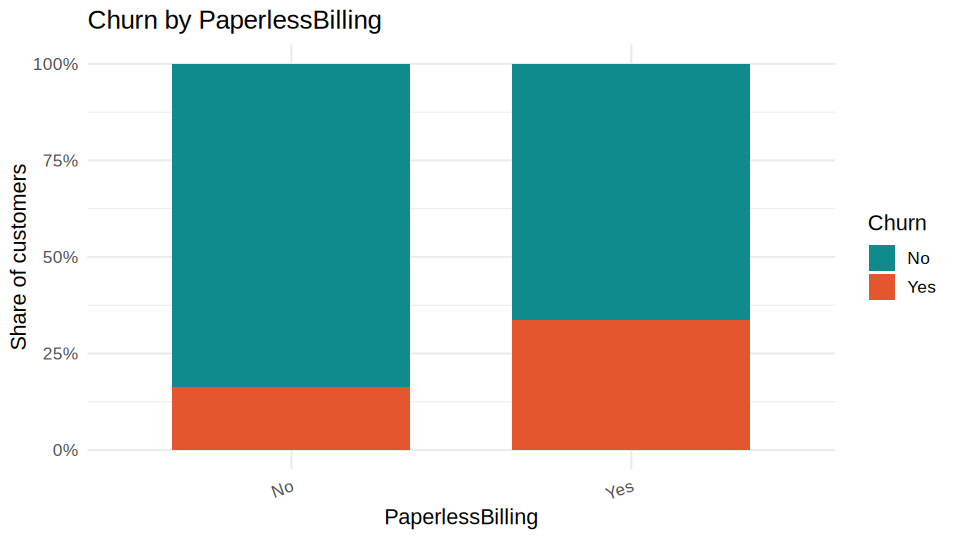

In [ ]:
# Other customer / service attributes
for (v in c("gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "OnlineSecurity", "TechSupport", "PaperlessBilling")) {
  print(plot_churn_by(v))
}

### 9.3 Churn rate by category (table)

In [ ]:
churn_rate_by <- function(var) {
  churn %>%
    group_by(.data[[var]]) %>%
    summarise(customers = n(),
              churned   = sum(Churn == "Yes"),
              churn_rate = round(100 * mean(Churn == "Yes"), 1),
              .groups = "drop") %>%
    arrange(desc(churn_rate))
}

churn_rate_by("Contract")
churn_rate_by("InternetService")
churn_rate_by("PaymentMethod")
churn_rate_by("SeniorCitizen")

Contract,customers,churned,churn_rate
<fct>,<int>,<int>,<dbl>
Month-to-month,3875,1655,42.7
One year,1472,166,11.3
Two year,1685,48,2.8


InternetService,customers,churned,churn_rate
<fct>,<int>,<int>,<dbl>
Fiber optic,3096,1297,41.9
DSL,2416,459,19.0
No,1520,113,7.4


PaymentMethod,customers,churned,churn_rate
<fct>,<int>,<int>,<dbl>
Electronic check,2365,1071,45.3
Mailed check,1604,308,19.2
Bank transfer (automatic),1542,258,16.7
Credit card (automatic),1521,232,15.3


SeniorCitizen,customers,churned,churn_rate
<fct>,<int>,<int>,<dbl>
Yes,1142,476,41.7
No,5890,1393,23.7


### 9.4 Numeric variables: `tenure`, `MonthlyCharges`, `TotalCharges`

In [ ]:
churn %>%
  group_by(Churn) %>%
  summarise(across(c(tenure, MonthlyCharges, TotalCharges),
                   list(mean = ~ round(mean(.x), 2), median = ~ round(median(.x), 2)),
                   .names = "{.col}_{.fn}"),
            .groups = "drop")

Churn,tenure_mean,tenure_median,MonthlyCharges_mean,MonthlyCharges_median,TotalCharges_mean,TotalCharges_median
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
No,37.65,38,61.31,64.45,2555.34,1683.60
Yes,17.98,10,74.44,79.65,1531.80,703.55


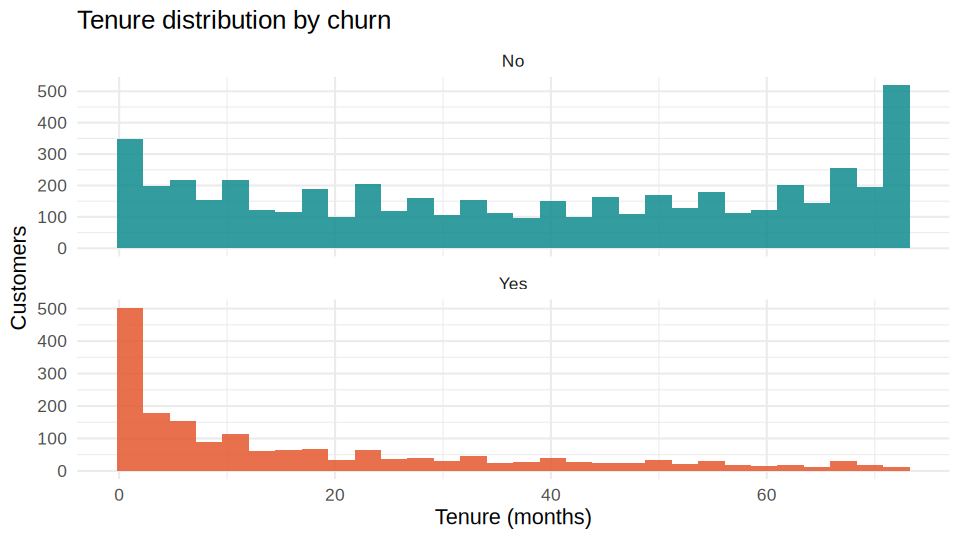

In [ ]:
ggplot(churn, aes(x = tenure, fill = Churn)) +
  geom_histogram(bins = 30, alpha = 0.85, position = "identity") +
  facet_wrap(~ Churn, ncol = 1, scales = "free_y") +
  scale_fill_manual(values = c("No" = "#0F8B8D", "Yes" = "#E4572E")) +
  labs(title = "Tenure distribution by churn", x = "Tenure (months)", y = "Customers") +
  theme(legend.position = "none")

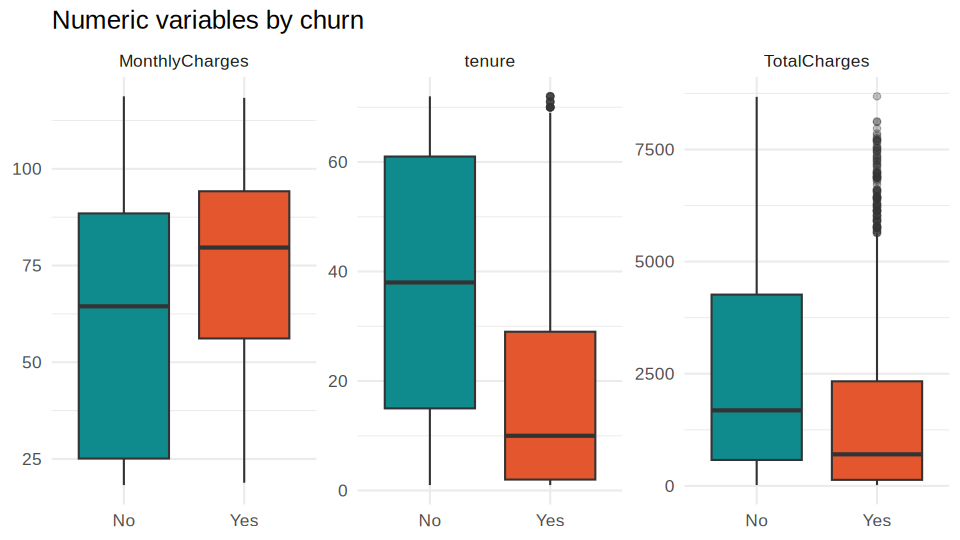

In [ ]:
churn %>%
  select(Churn, tenure, MonthlyCharges, TotalCharges) %>%
  pivot_longer(-Churn, names_to = "variable", values_to = "value") %>%
  ggplot(aes(x = Churn, y = value, fill = Churn)) +
  geom_boxplot(outlier.alpha = 0.3) +
  facet_wrap(~ variable, scales = "free_y") +
  scale_fill_manual(values = c("No" = "#0F8B8D", "Yes" = "#E4572E")) +
  labs(title = "Numeric variables by churn", x = NULL, y = NULL) +
  theme(legend.position = "none")

### 9.5 Correlation between numeric variables

In [ ]:
round(cor(churn[, c("tenure", "MonthlyCharges", "TotalCharges")]), 2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


`TotalCharges` is closely related to `tenure` and `MonthlyCharges` (it is roughly their product), so these variables can be correlated with each other. This is checked again with variance inflation factors in Section 10.

## 10. Logistic Regression

Logistic Regression is used because the target, **Churn**, is binary. The model estimates the log-odds of a customer churning from all the other variables.

### 10.1 Fit the model on the training set

In [ ]:
log_model <- glm(Churn ~ ., data = train, family = binomial)
summary(log_model)


Call:
glm(formula = Churn ~ ., family = binomial, data = train)

Coefficients:
                                       Estimate Std. Error z value Pr(>|z|)    
(Intercept)                           1.0746695  0.9571525   1.123 0.261532    
genderMale                           -0.0482269  0.0771304  -0.625 0.531797    
SeniorCitizenYes                      0.1200467  0.1014491   1.183 0.236683    
PartnerYes                           -0.0910761  0.0918164  -0.992 0.321228    
DependentsYes                        -0.0843260  0.1068161  -0.789 0.429849    
tenure                               -0.0621135  0.0074487  -8.339  < 2e-16 ***
PhoneServiceYes                       0.0233358  0.7635434   0.031 0.975618    
MultipleLinesYes                      0.3794100  0.2078464   1.825 0.067935 .  
InternetServiceFiber optic            1.5613737  0.9372764   1.666 0.095741 .  
InternetServiceNo                    -1.5047493  0.9480893  -1.587 0.112481    
OnlineSecurityYes                    -0.

### 10.2 Significant predictors

Predictors with p-value < 0.05 are listed below. A positive coefficient raises the odds of churn, and a negative coefficient lowers them.

In [ ]:
coef_tbl <- as.data.frame(summary(log_model)$coefficients)
colnames(coef_tbl) <- c("Estimate", "StdError", "z_value", "p_value")
coef_tbl$Term <- rownames(coef_tbl)
rownames(coef_tbl) <- NULL

sig_tbl <- coef_tbl %>%
  filter(Term != "(Intercept)", p_value < 0.05) %>%
  arrange(p_value) %>%
  mutate(across(c(Estimate, StdError, z_value), ~ round(.x, 3)),
         p_value = signif(p_value, 3)) %>%
  select(Term, Estimate, StdError, z_value, p_value)

sig_tbl

Term,Estimate,StdError,z_value,p_value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
tenure,-0.062,0.007,-8.339,7.50e-17
ContractTwo year,-1.464,0.204,-7.179,7.04e-13
ContractOne year,-0.845,0.130,-6.481,9.11e-11
TotalCharges,0.000,0.000,4.328,1.50e-05
PaperlessBillingYes,0.302,0.088,3.415,6.38e-04
PaymentMethodElectronic check,0.290,0.112,2.576,9.99e-03


### 10.3 Odds ratios

Odds ratio = exp(coefficient). A value above 1 means the odds of churn increase for that category (or per unit increase for numeric variables), and a value below 1 means they decrease.

In [ ]:
ci <- exp(confint.default(log_model))   # Wald confidence intervals

or_tbl <- data.frame(
  Term      = names(coef(log_model)),
  OddsRatio = exp(coef(log_model)),
  Lower95   = ci[, 1],
  Upper95   = ci[, 2],
  row.names = NULL
) %>%
  filter(Term != "(Intercept)") %>%
  mutate(across(c(OddsRatio, Lower95, Upper95), ~ round(.x, 3))) %>%
  arrange(desc(OddsRatio))

cat("Largest increase in churn odds:\n"); print(head(or_tbl, 8))
cat("\nLargest decrease in churn odds:\n"); print(tail(or_tbl, 8))

Largest increase in churn odds:
                           Term OddsRatio Lower95 Upper95
1    InternetServiceFiber optic     4.765   0.759  29.916
2            StreamingMoviesYes     1.783   0.840   3.785
3                StreamingTVYes     1.680   0.795   3.552
4              MultipleLinesYes     1.461   0.972   2.196
5           PaperlessBillingYes     1.353   1.137   1.609
6 PaymentMethodElectronic check     1.336   1.072   1.666
7              SeniorCitizenYes     1.128   0.924   1.376
8           DeviceProtectionYes     1.125   0.748   1.693

Largest decrease in churn odds:
                        Term OddsRatio Lower95 Upper95
16             DependentsYes     0.919   0.746   1.133
17                PartnerYes     0.913   0.763   1.093
18 PaymentMethodMailed check     0.905   0.692   1.183
19            TechSupportYes     0.880   0.580   1.335
20         OnlineSecurityYes     0.807   0.535   1.217
21          ContractOne year     0.429   0.333   0.555
22          ContractTwo year

### 10.4 Multicollinearity check (VIF)

In [ ]:
# Generalised VIF (GVIF^(1/(2*Df)) above ~2 suggests notable collinearity)
vif_vals <- car::vif(log_model)
round(vif_vals, 2)

,GVIF,Df,GVIF^(1/(2*Df))
gender,1.01,1,1.00
SeniorCitizen,1.15,1,1.07
Partner,1.36,1,1.17
Dependents,1.29,1,1.14
tenure,16.09,1,4.01
PhoneService,32.83,1,5.73
MultipleLines,7.19,1,2.68
InternetService,381.13,2,4.42
OnlineSecurity,5.03,1,2.24
OnlineBackup,6.20,1,2.49


Note: `tenure`, `MonthlyCharges` and `TotalCharges`, along with the internet service variables, often show high VIF values because they are related to each other. The model is kept as it is, since the goal here is prediction and understanding broad patterns, but individual coefficients of correlated variables should be interpreted with care.

## 11. Model Evaluation

The model is evaluated on the **test set** (data it has not seen) using appropriate classification metrics.

### 11.1 Predicted probabilities and confusion matrix (threshold = 0.5)

In [ ]:
test_prob <- predict(log_model, newdata = test, type = "response")
test_pred <- factor(ifelse(test_prob >= 0.5, "Yes", "No"), levels = c("No", "Yes"))

cm <- confusionMatrix(test_pred, test$Churn, positive = "Yes")
cm

Confusion Matrix and Statistics

          Reference
Prediction   No  Yes
       No  1385  229
       Yes  163  331
                                          
               Accuracy : 0.814           
                 95% CI : (0.7968, 0.8304)
    No Information Rate : 0.7343          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.5048          
                                          
 Mcnemar's Test P-Value : 0.001027        
                                          
            Sensitivity : 0.5911          
            Specificity : 0.8947          
         Pos Pred Value : 0.6700          
         Neg Pred Value : 0.8581          
             Prevalence : 0.2657          
         Detection Rate : 0.1570          
   Detection Prevalence : 0.2343          
      Balanced Accuracy : 0.7429          
                                          
       'Positive' Class : Yes             
                        

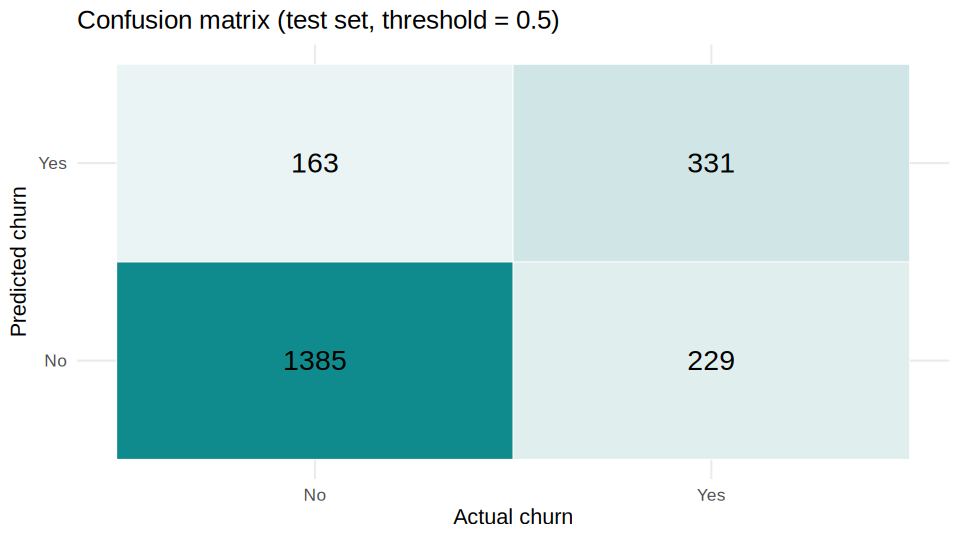

In [ ]:
# Confusion matrix as a heat-map
as.data.frame(cm$table) %>%
  ggplot(aes(x = Reference, y = Prediction, fill = Freq)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = Freq), size = 6) +
  scale_fill_gradient(low = "#EAF4F4", high = "#0F8B8D") +
  labs(title = "Confusion matrix (test set, threshold = 0.5)",
       x = "Actual churn", y = "Predicted churn") +
  theme(legend.position = "none")

### 11.2 Classification metrics

In [ ]:
metrics_05 <- data.frame(
  Metric = c("Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1 score"),
  Value  = round(c(cm$overall["Accuracy"],
                   cm$byClass["Precision"],
                   cm$byClass["Recall"],
                   cm$byClass["Specificity"],
                   cm$byClass["F1"]), 3),
  row.names = NULL
)
metrics_05

Metric,Value
<chr>,<dbl>
Accuracy,0.814
Precision,0.670
Recall (Sensitivity),0.591
Specificity,0.895
F1 score,0.628


- **Accuracy**: share of all customers classified correctly.
- **Precision**: of the customers predicted to churn, the share that really churned.
- **Recall**: of the customers who really churned, the share the model caught.
- **F1 score**: balance between precision and recall.

Because only a minority of customers churn, accuracy alone can look good even if many churners are missed, so recall and F1 are important here.

### 11.3 ROC curve and AUC

AUC: 0.856 


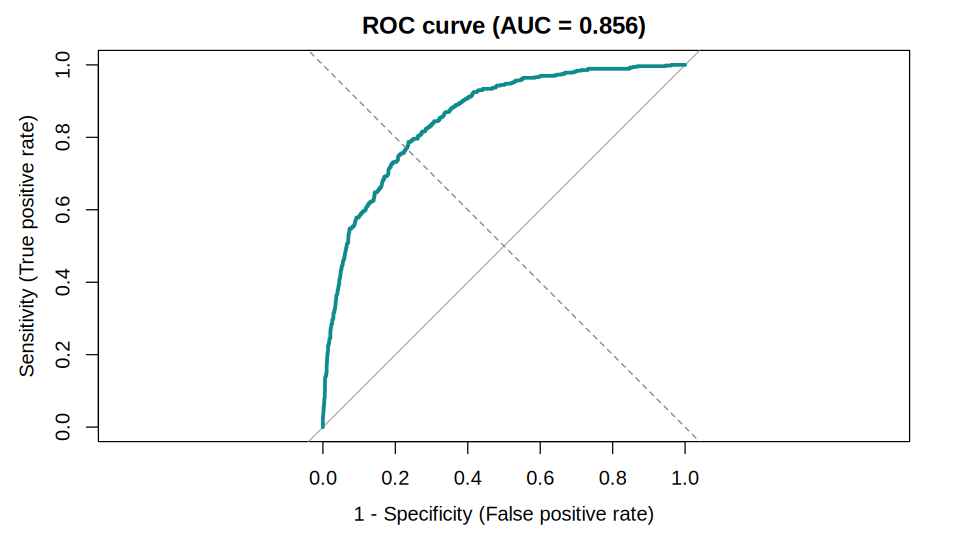

In [ ]:
roc_obj <- roc(response = test$Churn, predictor = test_prob,
               levels = c("No", "Yes"), direction = "<", quiet = TRUE)

auc_value <- as.numeric(auc(roc_obj))
cat("AUC:", round(auc_value, 3), "\n")

plot(roc_obj, col = "#0F8B8D", lwd = 3, legacy.axes = TRUE,
     main = paste0("ROC curve (AUC = ", round(auc_value, 3), ")"),
     xlab = "1 - Specificity (False positive rate)",
     ylab = "Sensitivity (True positive rate)")
abline(a = 0, b = 1, lty = 2, col = "grey50")

### 11.4 Choosing a better threshold

The default cut-off of 0.5 is not always best for an imbalanced target. The threshold that maximises *sensitivity + specificity* (Youden's index) is found on the ROC curve and the model is re-evaluated with it.

In [ ]:
best <- coords(roc_obj, x = "best", best.method = "youden",
               ret = c("threshold", "sensitivity", "specificity"), transpose = FALSE)
best_threshold <- best$threshold[1]
cat("Best threshold (Youden):", round(best_threshold, 3), "\n")

pred_best <- factor(ifelse(test_prob >= best_threshold, "Yes", "No"), levels = c("No", "Yes"))
cm_best <- confusionMatrix(pred_best, test$Churn, positive = "Yes")
cm_best

Best threshold (Youden): 0.306 


Confusion Matrix and Statistics

          Reference
Prediction   No  Yes
       No  1182  119
       Yes  366  441
                                          
               Accuracy : 0.7699          
                 95% CI : (0.7514, 0.7877)
    No Information Rate : 0.7343          
    P-Value [Acc > NIR] : 9.736e-05       
                                          
                  Kappa : 0.4831          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7875          
            Specificity : 0.7636          
         Pos Pred Value : 0.5465          
         Neg Pred Value : 0.9085          
             Prevalence : 0.2657          
         Detection Rate : 0.2092          
   Detection Prevalence : 0.3828          
      Balanced Accuracy : 0.7755          
                                          
       'Positive' Class : Yes             
                        

In [ ]:
comparison <- data.frame(
  Metric = c("Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1 score"),
  `Threshold 0.5` = round(c(cm$overall["Accuracy"], cm$byClass["Precision"], cm$byClass["Recall"],
                            cm$byClass["Specificity"], cm$byClass["F1"]), 3),
  `Best threshold` = round(c(cm_best$overall["Accuracy"], cm_best$byClass["Precision"], cm_best$byClass["Recall"],
                             cm_best$byClass["Specificity"], cm_best$byClass["F1"]), 3),
  check.names = FALSE, row.names = NULL
)
comparison

Metric,Threshold 0.5,Best threshold
<chr>,<dbl>,<dbl>
Accuracy,0.814,0.770
Precision,0.670,0.546
Recall (Sensitivity),0.591,0.787
Specificity,0.895,0.764
F1 score,0.628,0.645


## 12. Results Summary

In [ ]:
cat("====== CASE STUDY RESULTS ======\n")
cat("Customers analysed (after cleaning):", nrow(churn), "\n")
cat("Overall churn rate                 :", round(100 * mean(churn$Churn == "Yes"), 1), "%\n")
cat("Training / test rows               :", nrow(train), "/", nrow(test), "\n\n")
cat("Test accuracy  (threshold 0.5)     :", round(cm$overall["Accuracy"], 3), "\n")
cat("Test recall    (threshold 0.5)     :", round(cm$byClass["Recall"], 3), "\n")
cat("Test precision (threshold 0.5)     :", round(cm$byClass["Precision"], 3), "\n")
cat("AUC                                :", round(auc_value, 3), "\n\n")
cat("Significant predictors (p < 0.05)  :", nrow(sig_tbl), "\n")
print(sig_tbl$Term)

====== CASE STUDY RESULTS ======
Customers analysed (after cleaning): 7032 
Overall churn rate                 : 26.6 %
Training / test rows               : 4924 / 2108 

Test accuracy  (threshold 0.5)     : 0.814 
Test recall    (threshold 0.5)     : 0.591 
Test precision (threshold 0.5)     : 0.67 
AUC                                : 0.856 

Significant predictors (p < 0.05)  : 6 
[1] "tenure"                        "ContractTwo year"             
[3] "ContractOne year"              "TotalCharges"                 
[5] "PaperlessBillingYes"           "PaymentMethodElectronic check"


## 13. Expected Outcome / Conclusion

- Identify customer and service characteristics associated with churn.
- Develop a Logistic Regression model for customer churn prediction.
- Evaluate the model using appropriate classification metrics.
- Use the results to understand customer churn patterns and support potential retention decisions.

The final documentation will present the analysis, visualizations, model results and conclusions.

**How to read the results:** use the significant predictors and odds ratios (Section 10) to see which customer and service characteristics are linked to higher or lower churn, the churn-rate tables and plots (Section 9) to see those patterns in the raw data, and the accuracy, precision, recall, F1 and AUC values (Section 11) to judge how well the model predicts churn. Customers with a high predicted churn probability are the natural targets for retention offers.